# Explore the Yelp data (McDonald's and IKEA)

In this notebook, we will:
1. Compare locations and review ratings of both chains.
2. Read reviews and search for a topic.
3. Prepare an anonymized sample of 250 reviews per chain for notebooks 03–05.

**Data:** put `llm_fundamentals_data.zip` from Moodle into `data/`. Run this notebook once to create the anonymized sample; later exercises reuse the saved files. No API key is needed.


## Libraries and settings

In [1]:
# Libraries
import os
import platform
import zipfile
from datetime import datetime
from pathlib import Path
from platform import python_version

import matplotlib.pyplot as plt
import pandas as pd
from presidio_analyzer import AnalyzerEngine
from presidio_analyzer.nlp_engine import NlpEngineProvider
from presidio_anonymizer import AnonymizerEngine

# Folder with the data (relative to the folder of this notebook)
DATA = Path("../data")

# Show current working directory
print(os.getcwd())

/workspaces/llm_fundamentals/01_Explore_Yelp_Data


## Unzip the data

Unpacks `data/llm_fundamentals_data.zip` from Moodle into `data`. Run this once before loading the CSV files.

In [2]:
# Unpack the Moodle zip into data/
zip_path = DATA / "llm_fundamentals_data.zip"
if not zip_path.exists():
    # Stop quietly: show only a hint instead of a traceback
    class MissingData(Exception):
        def _render_traceback_(self):
            return [
                "Stopped: data/llm_fundamentals_data.zip not found.\n\n"
                "Hint: download it from Moodle and drag it onto the folder data "
                "(see README.md, section 'Data'), then run this cell again."
            ]
    raise MissingData()
with zipfile.ZipFile(zip_path) as archive:
    archive.extractall(DATA)
print("Data unpacked.")

Data unpacked.


## Part 1: The locations

### Import the business records

In [3]:
# Read the McDonald's and IKEA locations
df_bus = pd.read_csv(DATA / "businesses_mcdonalds_ikea.csv")

# Shape and first rows
print(df_bus.shape)
df_bus.head(5)


(718, 7)


,chain,business_id,name,city,state,stars,review_count
0,McDonald's,yM8LlTInbQH4FwWC97lz6w,McDonald's,St. Louis,MO,1.5,100
1,McDonald's,aNXw3PkXVt8ANwLyCfcmpg,McDonald's,Lansdale,PA,1.5,17
2,McDonald's,gb7JjRJtzWDsIWpJihZhBQ,McDonald's,Pennsville,NJ,2.0,20
3,McDonald's,9qxMhGWjGsuPUoQB3Y74Wg,McDonald's,St. Louis,MO,1.5,62
4,McDonald's,A1lAqN3SOaBLoo6NqVcy4Q,McDonald's,Brandon,FL,2.0,6


### Number of locations and reviews per chain

In [4]:
# Locations, reviews and mean rating per chain
summary = df_bus.groupby("chain").agg(
    locations=("business_id", "count"),
    reviews=("review_count", "sum"),
    mean_stars=("stars", "mean"),
)
summary.round(2)


,locations,reviews,mean_stars
chain,,,
IKEA,8,1688,3.38
McDonald's,710,17427,1.86


### Average rating: per location vs. per review

`mean_stars` counts every location once. To give locations with more reviews more weight, we weight their ratings by their review counts. These business-file ratings are rounded, so this is an approximation of a review-level average, not an exact mean of the individual review stars.

In [5]:
# Weighted average: sum of (stars x reviews) divided by the sum of reviews
df_bus["stars_x_reviews"] = df_bus["stars"] * df_bus["review_count"]
totals = df_bus.groupby("chain")[["stars_x_reviews", "review_count"]].sum()
summary["weighted_stars"] = totals["stars_x_reviews"] / totals["review_count"]

summary.round(2)

,locations,reviews,mean_stars,weighted_stars
chain,,,,
IKEA,8,1688,3.38,3.31
McDonald's,710,17427,1.86,1.78


## Part 2: Reviews of both chains

### Import the reviews

In [6]:
# Read the reviews of both chains
ikea = pd.read_csv(DATA / "ikea_reviews.csv", parse_dates=["date"])
mcdonalds = pd.read_csv(DATA / "mcdonalds_reviews.csv", parse_dates=["date"])

# Add the chain name and combine both tables into one
ikea["chain"] = "IKEA"
mcdonalds["chain"] = "McDonald's"
df = pd.concat([ikea, mcdonalds], ignore_index=True)

# Number of reviews and mean rating per chain
overview = df.groupby("chain")["stars"].agg(["count", "mean"])
print(overview.round(2))
df[["chain", "stars", "text"]].head()

            count  mean
chain                  
IKEA         1743  3.26
McDonald's  18280  1.78


,chain,stars,text
0,IKEA,4.0,Breakfast for .99 cents. I love Sweden.\n\n\nY...
1,IKEA,3.0,"My advice to any Philadelphia IKEA-shopper, AV..."
2,IKEA,3.0,Ikea is a confusing labyrinth made up of Swedi...
3,IKEA,4.0,As much as is wrong with IKEA (their maze-like...
4,IKEA,5.0,I heart IKEA! I will mecca down here from Alle...


### Star distribution of the reviews

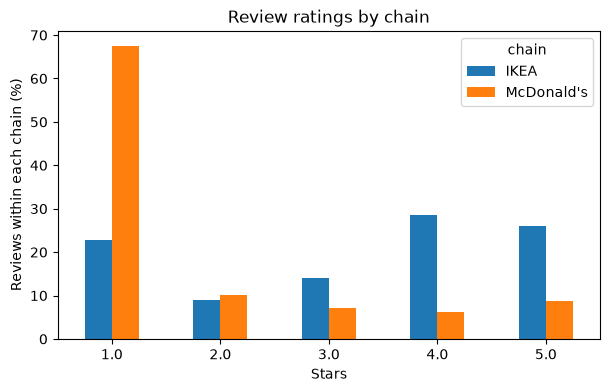

In [7]:
# Percentages make chains with different review counts comparable
counts = pd.crosstab(df["stars"], df["chain"], normalize="columns") * 100

counts.plot.bar(figsize=(7, 4))
plt.title("Review ratings by chain")
plt.xlabel("Stars")
plt.ylabel("Reviews within each chain (%)")
plt.xticks(rotation=0)
plt.show()

Compare the two star distributions: are reviews concentrated at the extremes or in the middle? Describe what you actually see.

A **J-shape** (many high ratings, another peak at low ratings, fewer in between) is common in online reviews. People choose whether to write a review. Even a perfect summary describes those reviewers, not all customers.

## Part 3: Read reviews

Choose a chain and read one example with 1, 3 and 5 stars. Does the text fit the rating? This prepares the distinction between ratings and text sentiment in notebook 03.

In [8]:
# Change to 'IKEA' to inspect the other chain
CHAIN = "McDonald's"
reviews = df[df["chain"] == CHAIN]

# One example review with 1, 3 and 5 stars (fixed seed)
for stars in [1, 3, 5]:
    examples = reviews[reviews["stars"] == stars]
    review = examples.sample(1, random_state=42).iloc[0]
    print(CHAIN, "|", stars, "stars |", review["city"])

    # Print the first 500 characters of the text
    print(review["text"][:500], "\n")

McDonald's | 1 stars | Indianapolis
If I could give a zero I would.  How does this person keep their franchise?  Has McDonald's stoooped this low????  I give a place a break..once...even twice.  I have NEVER had good service here. Doese corporate EVER visit this place?????  This is a sh!t show of a restaraunt.  Wow McDonalds.... 

McDonald's | 3 stars | Sahuarita
This particular McDonald's is very close to home.  Very convenient when I am busy and need to grab a bite to eat or to grab a little snack to hold us over.  This location is open 24 hours, so that's a plus if you are in the mood for a midnight snack or coming home from a night out!  This includes the dining room too!

For the most part, the restaurant is very clean, but at times when it's very busy, I've been there when the trash bins are at its capacity and the dining area is packed.  Again, ju 

McDonald's | 5 stars | Tampa
I got a Happy Fathers Day from an employee that works here & I'm not even a Father. Very nice employee

### Search for a topic

In [9]:
# TODO: try 'fries' for McDonald's or 'assembly' for IKEA
topic = "drive"

# Reviews that contain the search term
hits = reviews[reviews["text"].str.contains(topic, case=False, regex=False)]
print(f"{CHAIN}: {len(hits)} reviews match '{topic}'")
print(
    f"Mean stars: {hits['stars'].mean():.2f} "
    f"(chain: {reviews['stars'].mean():.2f})"
)
hits[["stars", "store", "text"]].head(5)

McDonald's: 6055 reviews match 'drive'
Mean stars: 1.67 (chain: 1.78)


,stars,store,text
1747,4.0,McDonald's,4 stars for being there for me after midnight ...
1750,2.0,McDonald's,No drive-through? And it's off of a freeway? ...
1752,1.0,McDonald's,Hahahaha... so happy to see these other 2 revi...
1753,3.0,McDonald's,It's a McDonald's... so you already know what ...
1754,3.0,McDonald's,It's worth noting this is the closest McDonald...


## Part 4: Prepare a sample for the API notebooks

Reviews can contain names, phone numbers and other personal details. **We never send personal data to an external API.** Notebooks 03–05 therefore use a prepared sample:

1. Draw a random sample of **500 reviews: 250 per chain**. That is enough for all exercises and keeps the notebooks fast.
2. Remove personal details: names of people, e-mail addresses, phone numbers and account or ID numbers. This runs on this computer (libraries Presidio and spaCy), not through an API. Company names, places and dates stay, because the model needs them to understand a review.
3. Check the result and save it.

### Set up the anonymization

Presidio works in two steps: the **analyzer** finds personal details in a text, the **anonymizer** replaces them with a placeholder such as `<PERSON>`. Our function `anonymize()` runs both steps for one text.

In [10]:
# Details that identify a person (Presidio entity types)
ENTITIES = [
    "PERSON",
    "EMAIL_ADDRESS",
    "PHONE_NUMBER",
    "CREDIT_CARD",
    "IBAN_CODE",
    "IP_ADDRESS",
    "US_SSN",
    "US_PASSPORT",
    "US_DRIVER_LICENSE",
    "US_BANK_NUMBER",
]

# The analyzer finds personal details with a small English language model
provider = NlpEngineProvider(
    nlp_configuration={
        "nlp_engine_name": "spacy",
        "models": [{"lang_code": "en", "model_name": "en_core_web_sm"}],
    }
)
analyzer = AnalyzerEngine(nlp_engine=provider.create_engine())

# The anonymizer replaces what the analyzer found
anonymizer = AnonymizerEngine()


def anonymize(text):
    """Replace personal details in one text, on this computer."""
    # Find personal details; ignore findings with a low confidence score
    found = analyzer.analyze(
        text=text, language="en", entities=ENTITIES, score_threshold=0.35
    )

    # Replace every finding with a placeholder such as <PERSON>
    result = anonymizer.anonymize(text=text, analyzer_results=found)
    return result.text

### How `anonymize()` works: one example

In [11]:
# A made-up text with a name, a phone number and an e-mail address
example = (
    "I asked for John Smith at the IKEA store in Tampa. "
    "Call me on 813-555-0199 or write to john.smith@example.com."
)

# Before and after anonymization
print(example)
print(anonymize(example))

I asked for John Smith at the IKEA store in Tampa. Call me on 813-555-0199 or write to john.smith@example.com.
I asked for <PERSON> at the IKEA store in Tampa. Call me on <PHONE_NUMBER> or write to <EMAIL_ADDRESS>.


### Draw the sample

We give both chains equal space so McDonald's larger dataset does not dominate the exercises. This is a teaching sample, not the original distribution.

Some review texts appear more than once in the data. We keep each text once. We also leave out the three example reviews that notebook 03 shows to the model: a review used as an example must not be used again to test the model.

In [12]:
# Reviews whose text appears more than once
duplicates = df[df.duplicated("text", keep=False)]
print("Rows with a text that appears more than once:", len(duplicates))

# Keep each text once and leave out the three example reviews of notebook 03
examples = pd.read_json(DATA / "fewshot_examples.json")
unique = df.drop_duplicates("text")
unique = unique[~unique["text"].isin(examples["text"])]
print("All reviews:", len(df), "| unique, without the examples:", len(unique))

Rows with a text that appears more than once: 79
All reviews: 20023 | unique, without the examples: 19981


In [13]:
# 250 reviews per chain, with a fixed seed for reproducibility
sample = unique.groupby("chain").sample(n=250, random_state=42)
columns = ["chain", "store", "city", "stars", "date", "text"]
sample = sample[columns].reset_index(drop=True)

# Short IDs R001 ... R500: easy to read and to cite later
ids = []
for i in range(1, len(sample) + 1):
    ids.append(f"R{i:03d}")
sample.insert(0, "id", ids)

# Sampled reviews per chain and star rating
pd.crosstab(sample["chain"], sample["stars"])

stars,1.0,2.0,3.0,4.0,5.0
chain,,,,,
IKEA,50,25,38,79,58
McDonald's,179,16,15,13,27


### Anonymize the sample

In [14]:
# Keep the original text for the comparison below, then anonymize locally
sample["original"] = sample["text"]
sample["text"] = sample["original"].apply(anonymize)

# Reviews whose text changed
changed = sample[sample["text"] != sample["original"]]
print("Reviews with at least one replacement:", len(changed), "of", len(sample))

Reviews with at least one replacement: 107 of 500


### Check the result

Automatic anonymization makes mistakes: it can miss a name, and it can remove harmless words. Compare some texts before and after.

In [15]:
# Before and after, for five changed reviews
pd.set_option("display.max_colwidth", 400)
changed[["id", "original", "text"]].head(5)


,id,original,text
1,R002,Returned to IKEA three days later. Once again the bin was empty. I asked an employee at one of the credit desks and he looked up the item I wanted. He realized the nightstand was out on display away from the aisle and bin the website said it would be in. Sure enough there were plenty of nightstand boxes at the display location. Appearently the display had been there on Saturday as well and the...,Returned to IKEA three days later. Once again the <PERSON> was empty. I asked an employee at one of the credit desks and he looked up the item I wanted. He realized the nightstand was out on display away from the aisle and <PERSON> the website said it would be in. Sure enough there were plenty of nightstand boxes at the display location. Appearently the display had been there on Saturday as we...
7,R008,Went to IKEA on a Sunday afternoon although it was still busy not as busy as going on a Saturday I was shopping for a new desk of course I found one. The place was very clean and there was plenty help around definitely will be going again. Looks like Sunday is a good day to go but also I'm told if you can go in the middle of the day on a weekday will be even better.,Went to IKEA on a Sunday afternoon although it was still busy not as busy as going on a Saturday I was shopping for a new desk of course I found one. The place was very clean and there was plenty help around definitely will be going again. <PERSON> like Sunday is a good day to go but also I'm told if you can go in the middle of the day on a weekday will be even better.
16,R017,"The Returns and Exchanges department of this location is the worst. Understaffed and the staff that works (I use that term very lightly)there meanders around at their own speed with no sense of urgency. They are almost saying, ""I have to be here all day and now you will be too."" \n\nUnbelievable. It's like the waiting room in Beetlejuice, but way worse.\n\n\nWorst place ever.","The Returns and Exchanges department of this location is the worst. <PERSON> and the staff that works (I use that term very lightly)there meanders around at their own speed with no sense of urgency. They are almost saying, ""I have to be here all day and now you will be too."" \n\nUnbelievable. It's like the waiting room in Beetlejuice, but way worse.\n\n\nWorst place ever."
17,R018,"Finally a store in St. LOUIS, the have so pretty cool stuff and some very cool displays, to get ideas from!!! IKEA, Thanks for coming to the LOU!!! Store is beautiful and ample parking, covered and lot parking!!!","Finally a store in St. LOUIS, the have so pretty cool stuff and some very cool displays, to get ideas from!!! IKEA, Thanks for coming to the LOU!!! <PERSON> is beautiful and ample parking, covered and lot parking!!!"
18,R019,"Ikea a great place for the whole family! We come her because it's a great place to go, shop with the wife and best of all ""infant friendly"". It's getting harder to find a place to eat without my 2 year old freaking out after 15 minutes sitting down. IKEA has just enough running around and quick cafeteria to get him good to go! The food is different and comfort food all mixed up in cafeteria li...","Ikea a great place for the whole family! We come her because it's a great place to go, shop with the wife and best of all ""infant friendly"". It's getting harder to find a place to eat without my 2 year old freaking out after 15 minutes sitting down. IKEA has just enough running around and quick cafeteria to get him good to go! The food is different and comfort food all mixed up in cafeteria li..."


**Your turn:** read a few more rows, for example with `sample[['id', 'original', 'text']].sample(5)`. Include texts that the detector left unchanged: missed details will not appear in `changed`. If you still find a personal detail, replace the text of this review in the next cell. Places and dates can also identify someone in context; remove them by hand when needed.

In [16]:
# TODO (only if needed): correct a text by hand, e.g.
# sample.loc[sample['id'] == 'R007', 'text'] = 'your corrected text'


### Save the sample

We save only the anonymized texts. The file stays in `data/processed/`, which Git ignores.

In [17]:
# Save the sample without the original texts
os.makedirs(DATA / "processed", exist_ok=True)
sample.drop(columns="original").to_csv(
    DATA / "processed/reviews_sample.csv", index=False
)
print("Saved", len(sample), "reviews: data/processed/reviews_sample.csv")

Saved 500 reviews: data/processed/reviews_sample.csv


## Check your understanding

Answer briefly using the outputs above. Try first, then open the hints.

1. What does the star distribution tell you about the people who write reviews? Why is it not a survey of all customers?
2. Why can the average rating per location differ from the average weighted by the number of reviews?
3. Why do we sample 250 reviews per chain and exclude duplicate texts and few-shot examples?
4. Choose one anonymized example. What was removed, what stayed, and what still needs a human check?
5. Which file should notebooks 03–05 use, and why must it contain only the checked, anonymized texts?

**Your answers:**

1. …
2. …
3. …
4. …
5. …

<details>
<summary style="color: #B8860B; font-weight: bold; cursor: pointer;">Hints for self-check</summary>

1. Reviewers select themselves; very happy and very unhappy customers may be overrepresented.

2. The first counts each location once; the second gives locations with more reviews more weight.

3. Equal sample sizes prevent the larger chain from dominating the exercises; they do not represent the original proportions. Duplicates give repeated texts extra weight. Reusing a solved prompt example for evaluation makes the evaluation too easy.

4. Use your actual output: personal names, e-mail addresses and phone numbers should be removed. Check for missed personal details and unnecessary replacements.

5. Use data/processed/reviews_sample.csv. Later notebooks send texts to an external API; the original texts must stay out of that file.

</details>

### Jupyter notebook --footer info-- (please always provide this at the end of each notebook)

In [18]:
# Show operating system, date/time and Python version
print("-----------------------------------")
print(os.name.upper())
print(platform.system(), "|", platform.release())
print("Datetime:", datetime.now().strftime("%Y-%m-%d %H:%M:%S"))
print("Python Version:", python_version())
print("-----------------------------------")


-----------------------------------
POSIX
Linux | 6.8.0-1070-azure
Datetime: 2026-11-13 09:32:48
Python Version: 3.11.18
-----------------------------------
